In [2]:
import geopandas as gpd
from shapely.geometry import box
import subprocess
import requests

sierra_geom = box(-119.5, 35.5, -118.5, 37.5)
gdf = gpd.GeoDataFrame({"geometry": [sierra_geom]}, crs="EPSG:4326")
out_path = "../data/kml/sierra_pilot.geojson"
gdf.to_file(out_path, driver="GeoJSON")

assessment_id = "climate_impact_curves_sierra_2016_2018"
aoi_gs = f"gs://fire-biomass/{assessment_id}/perimeter.geojson"
subprocess.run(["gsutil", "cp", out_path, aoi_gs], check=True)

url = "https://europe-west2-artio-carbon.cloudfunctions.net/biomassagbd-trigger"

base_body = {
    "PROJECT_ASSESSMENT_ID": assessment_id,
    "AOI_GS": aoi_gs,
    "PIPELINE_COMMAND": "prepare-data",
    "AUTO_TRIGGER_STAGE2": True,
    "MODEL_IDS": "18693595-3,18693569-4",
    "PROJECT_ID": "artio-carbon",
    "STAGING_BUCKET": "gs://artio-vertex-staging/vertex-staging",
    "SERVICE_ACCOUNT": "prod-service-account@artio-carbon.iam.gserviceaccount.com",
}

for year, quarter in [("2016", "Q1"), ("2018", "Q4")]:
    body = {**base_body, "YEARS": [year], "QUARTERS": [quarter]}
    r = requests.post(url, json=body)
    print(year, quarter, r.status_code, r.text[:300])


Copying file://../data/kml/sierra_pilot.geojson [Content-Type=application/geo+json]...
/ [0 files][    0.0 B/  348.0 B]                                                

KeyboardInterrupt: 

/ [1 files][  348.0 B/  348.0 B]                                                
Operation completed over 1 objects/348.0 B.                                      


In [1]:
import subprocess

def check_job_state(assessment_id):
    result = subprocess.run(
        ["gcloud", "ai", "custom-jobs", "list", "--region=europe-west2", "--project=artio-carbon",
         f"--filter=displayName:biomassagbd-stage1-{assessment_id}*",
         "--format=value(displayName,state)"],
        capture_output=True, text=True,
    )
    print(result.stdout or "(no matching jobs found yet)")
    return result.stdout

def check_file_counts(assessment_id):
    result = subprocess.run(
        ["gsutil", "ls", f"gs://artio-projects/project-assessment/{assessment_id}/biomass/*/*/predictions/*/*.tif"],
        capture_output=True, text=True,
    )
    n_files = len([l for l in result.stdout.splitlines() if l.strip()])

    s2_result = subprocess.run(
        ["gsutil", "ls", f"gs://artio-projects/project-assessment/{assessment_id}/biomass/*/*/composite/s2/*.tif"],
        capture_output=True, text=True,
    )
    n_tiles = len([l for l in s2_result.stdout.splitlines() if l.strip()])

    expected = n_tiles * 2
    status = "COMPLETE" if n_files >= expected and n_tiles > 0 else f"incomplete ({n_files}/{expected})"
    print(assessment_id, f"tiles={n_tiles}, predictions={n_files}/{expected} -> {status}")

check_job_state(assessment_id)
check_file_counts(assessment_id)


NameError: name 'assessment_id' is not defined

In [9]:
assessment_id = "climate_impact_curves_sierra_2016_2018"

check_job_state(assessment_id)
check_file_counts(assessment_id)


biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2017-Q1-20261110-090957	JOB_STATE_SUCCEEDED
biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2018-Q4-20261109-140540	JOB_STATE_SUCCEEDED
biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2016-Q1-20261109-140540	JOB_STATE_FAILED

climate_impact_curves_sierra_2016_2018 tiles=14, predictions=0/28 -> incomplete (0/28)


In [10]:
import subprocess
result = subprocess.run(
    ["gcloud", "ai", "custom-jobs", "list", "--region=europe-west2", "--project=artio-carbon",
     f"--filter=displayName:biomassagbd-stage2-{assessment_id}*",
     "--format=value(displayName,state)"],
    capture_output=True, text=True
)
print(result.stdout)
print(result.stderr)


biomassagbd-stage2-climate_impact_curves_sierra_2016_2018-2017-Q1-20261110-220906	JOB_STATE_PENDING
biomassagbd-stage2-climate_impact_curves_sierra_2016_2018-2018-Q4-20261110-204552	JOB_STATE_PENDING

Using endpoint [https://europe-west2-aiplatform.googleapis.com/]



In [11]:
result = subprocess.run(
    ["gcloud", "ai", "custom-jobs", "list", "--region=europe-west2", "--project=artio-carbon",
     f"--filter=displayName:biomassagbd-stage2-{assessment_id}*",
     "--format=value(name)"],
    capture_output=True, text=True
)
print(result.stdout)


projects/454493654437/locations/europe-west2/customJobs/8177769326749679616
projects/454493654437/locations/europe-west2/customJobs/8020143339791712256



In [7]:
url = "https://europe-west2-artio-carbon.cloudfunctions.net/biomassagbd-trigger"
assessment_id = "climate_impact_curves_sierra_2016_2018"
aoi_gs = f"gs://fire-biomass/{assessment_id}/perimeter.geojson"
url = "https://europe-west2-artio-carbon.cloudfunctions.net/biomassagbd-trigger"

body_2017q1 = {
    "PROJECT_ASSESSMENT_ID": assessment_id,
    "AOI_GS": aoi_gs,
    "PIPELINE_COMMAND": "prepare-data",
    "AUTO_TRIGGER_STAGE2": True,
    "MODEL_IDS": "18693595-3,18693569-4",
    "PROJECT_ID": "artio-carbon",
    "STAGING_BUCKET": "gs://artio-vertex-staging/vertex-staging",
    "SERVICE_ACCOUNT": "prod-service-account@artio-carbon.iam.gserviceaccount.com",
    "YEARS": ["2017"],
    "QUARTERS": ["Q1"],
}

r = requests.post(url, json=body_2017q1)
print(r.status_code, r.text[:300])


200 {
  "project": "artio-carbon",
  "region": "europe-west2",
  "pipeline_command": "prepare-data",
  "auto_trigger_stage2": true,
  "jobs_submitted": [
    {
      "display_name": "biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2017-Q1-20261110-090957",
      "resource_name": "projects/4544


In [12]:
for aid, label in [(assessment_id, "sierra_2016_2018")]:
    check_job_state(aid)
    check_file_counts(aid)


biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2017-Q1-20261110-090957	JOB_STATE_SUCCEEDED
biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2018-Q4-20261109-140540	JOB_STATE_SUCCEEDED
biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2016-Q1-20261109-140540	JOB_STATE_FAILED

climate_impact_curves_sierra_2016_2018 tiles=14, predictions=28/28 -> COMPLETE


In [13]:
import subprocess, glob, os
import rasterio
import numpy as np
import matplotlib.pyplot as plt

TCO2E_TO_AGB = 1.72  # convert tCO2e/ha -> AGB Mg/ha

def download_predictions(assessment_id, year, quarter, model_id, out_dir="../data/raw/inhouse"):
    os.makedirs(out_dir, exist_ok=True)
    gs_path = f"gs://artio-projects/project-assessment/{assessment_id}/biomass/{year}/{quarter}/predictions/{model_id}/"
    subprocess.run(["gsutil", "-m", "cp", "-r", gs_path, out_dir], check=True)
    return os.path.join(out_dir, model_id.split("/")[-1] if model_id.endswith("/") else model_id)

for year, quarter in [("2017", "Q1"), ("2018", "Q4")]:
    for model_id in ["18693595-3", "18693569-4"]:
        download_predictions(assessment_id, year, quarter, model_id)


Copying gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/predictions/18693595-3/Q1_18693595-3_10SGG.tif...
Copying gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/predictions/18693595-3/Q1_18693595-3_11SKA.tif...
Copying gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/predictions/18693595-3/Q1_18693595-3_11SLB.tif...
Copying gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/predictions/18693595-3/Q1_18693595-3_11SKB.tif...
Copying gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/predictions/18693595-3/Q1_18693595-3_11SKV.tif...
Copying gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/predictions/18693595-3/Q1_18693595-3_11SLV.tif...
Copying gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/bi

In [1]:
import glob, os
import rasterio
from rasterio.merge import merge
from rasterio.vrt import WarpedVRT
from rasterio.warp import Resampling as WarpResampling
from rasterio.windows import from_bounds
import numpy as np
import matplotlib.pyplot as plt

TCO2E_TO_AGB = 1.72
TARGET_CRS = "EPSG:4326"
SIERRA_BOUNDS = (-119.5, 35.5, -118.5, 37.5)  # lon_min, lat_min, lon_max, lat_max
OUT_RES_DEG = 0.001  # ~100m at this latitude

def load_and_mosaic(out_dir, model_id, quarter_prefix, bounds=SIERRA_BOUNDS, res=OUT_RES_DEG, target_crs=TARGET_CRS):
    tifs = sorted(glob.glob(os.path.join(out_dir, model_id, f"{quarter_prefix}_*.tif")))
    vrts, srcs = [], []
    for t in tifs:
        src = rasterio.open(t)
        srcs.append(src)
        vrt = WarpedVRT(src, crs=target_crs, resampling=WarpResampling.bilinear)
        vrts.append(vrt)

    mosaic, transform = merge(
        vrts,
        bounds=bounds,
        res=(res, res),
    )
    for v in vrts:
        v.close()
    for s in srcs:
        s.close()
    agb = mosaic[0].astype("float32") / TCO2E_TO_AGB
    return agb, transform, target_crs

out_dir = "../data/raw/inhouse"

agb_2017q1_a, t17, crs17 = load_and_mosaic(out_dir, "18693595-3", "Q1")
agb_2018q4_a, t18, crs18 = load_and_mosaic(out_dir, "18693595-3", "Q4")

print(agb_2017q1_a.shape, agb_2018q4_a.shape)


(2000, 1000) (2000, 1000)


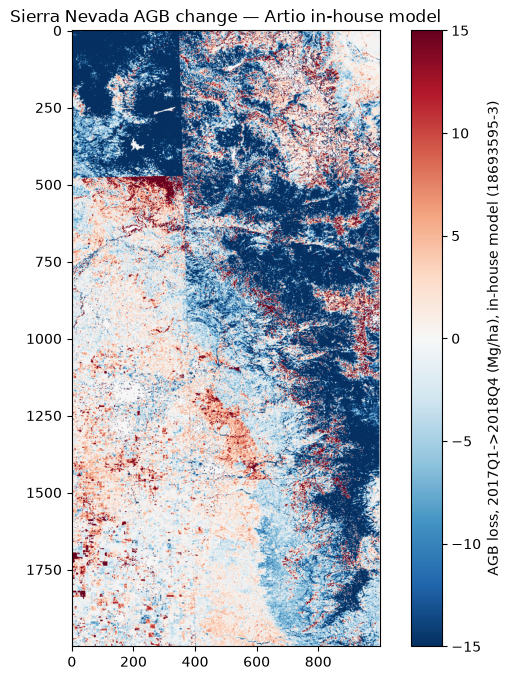

In [2]:
loss_inhouse_a = agb_2017q1_a - agb_2018q4_a

fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(loss_inhouse_a, cmap="RdBu_r", vmin=-15, vmax=15)
plt.colorbar(im, label="AGB loss, 2017Q1->2018Q4 (Mg/ha), in-house model (18693595-3)")
plt.title("Sierra Nevada AGB change — Artio in-house model")
plt.savefig("../data/raw/inhouse_loss_map_model_a.png", dpi=150)
plt.show()


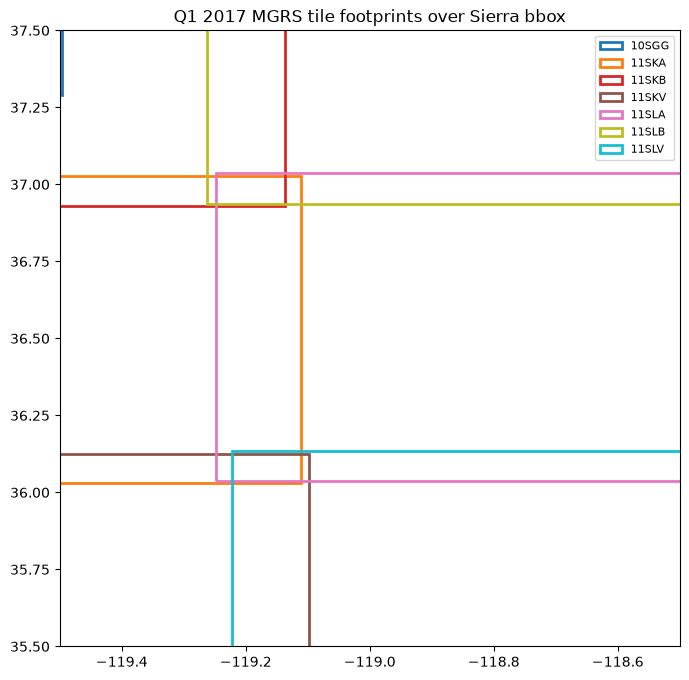

In [3]:
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.warp import Resampling as WarpResampling
import numpy as np
import matplotlib.pyplot as plt

tifs_q1 = sorted(glob.glob(os.path.join(out_dir, "18693595-3", "Q1_*.tif")))
fig, ax = plt.subplots(figsize=(8, 8))
colors = plt.cm.tab10(np.linspace(0, 1, len(tifs_q1)))

for i, t in enumerate(tifs_q1):
    with rasterio.open(t) as src:
        vrt = WarpedVRT(src, crs="EPSG:4326", resampling=WarpResampling.nearest)
        bounds = vrt.bounds
        tile_name = os.path.basename(t).split("_")[-1].replace(".tif", "")
        rect = plt.Rectangle((bounds.left, bounds.bottom), bounds.right-bounds.left, bounds.top-bounds.bottom,
                              fill=False, edgecolor=colors[i], linewidth=2, label=tile_name)
        ax.add_patch(rect)

ax.set_xlim(-119.5, -118.5)
ax.set_ylim(35.5, 37.5)
ax.legend(loc="upper right", fontsize=8)
ax.set_title("Q1 2017 MGRS tile footprints over Sierra bbox")
plt.show()


In [6]:
assessment_id = "climate_impact_curves_sierra_2016_2018"

result = subprocess.run(
    ["gsutil", "ls", "-r", f"gs://artio-projects/project-assessment/{assessment_id}/biomass/2017/Q1/"],
    capture_output=True, text=True,
)
print(result.stdout)
print(result.stderr)

gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/:
gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/pipeline-state.json

gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/:

gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/:
gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/10SGG_multimodal.tif
gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/11SKA_multimodal.tif
gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/11SKB_multimodal.tif
gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/11SKV_multimodal.tif
gs://artio-projects/p

In [7]:
result = subprocess.run(
    ["gsutil", "cat", f"gs://artio-projects/project-assessment/{assessment_id}/biomass/2017/Q1/pipeline-state.json"],
    capture_output=True, text=True,
)
print(result.stdout)


{
  "pipeline_status": "complete",
  "stage": "inference_complete",
  "version": "2.0",
  "timestamp": "2026-11-10T22:09:06.160038Z",
  "stage1_timestamp": "2026-11-10T22:09:06.160105Z",
  "tiles_processed": [
    "10SGG",
    "11SKA",
    "11SKB",
    "11SKV",
    "11SLA",
    "11SLB",
    "11SLV"
  ],
  "tiles_skipped": [],
  "composite_lookup": {
    "10SGG": "gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/10SGG_multimodal.tif",
    "11SKA": "gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/11SKA_multimodal.tif",
    "11SKB": "gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/11SKB_multimodal.tif",
    "11SKV": "gs://artio-projects/project-assessment/climate_impact_curves_sierra_2016_2018/biomass/2017/Q1/composite/multimodal/11SKV_multimodal.tif",
    "11SLA": "gs://artio-projects/projec

In [9]:
import requests

assessment_id = "climate_impact_curves_sierra_2016_2018"
aoi_gs = f"gs://fire-biomass/{assessment_id}/perimeter.geojson"
url = "https://europe-west2-artio-carbon.cloudfunctions.net/biomassagbd-trigger"

base_body = {
    "PROJECT_ASSESSMENT_ID": assessment_id,
    "AOI_GS": aoi_gs,
    "PIPELINE_COMMAND": "prepare-data",
    "AUTO_TRIGGER_STAGE2": True,
    "MODEL_IDS": "18693595-3,18693569-4",
    "PROJECT_ID": "artio-carbon",
    "STAGING_BUCKET": "gs://artio-vertex-staging/vertex-staging",
    "SERVICE_ACCOUNT": "prod-service-account@artio-carbon.iam.gserviceaccount.com",
}

# Same-quarter year-over-year: removes the Q1/Q4 seasonal mismatch confound
# (2017-Q1 vs 2018-Q4 already run and downloaded - Section 11)
for year, quarter in [("2017", "Q4"), ("2018", "Q4")]:
    body = {**base_body, "YEARS": [year], "QUARTERS": [quarter]}
    r = requests.post(url, json=body)
    print(year, quarter, r.status_code, r.text[:300])


2017 Q4 200 {
  "project": "artio-carbon",
  "region": "europe-west2",
  "pipeline_command": "prepare-data",
  "auto_trigger_stage2": true,
  "jobs_submitted": [
    {
      "display_name": "biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2017-Q4-20261113-114521",
      "resource_name": "projects/4544
2018 Q4 200 {
  "project": "artio-carbon",
  "region": "europe-west2",
  "pipeline_command": "prepare-data",
  "auto_trigger_stage2": true,
  "jobs_submitted": [
    {
      "display_name": "biomassagbd-stage1-climate_impact_curves_sierra_2016_2018-2018-Q4-20261113-114521",
      "resource_name": "projects/4544


In [ ]:
check_job_state(assessment_id)
check_file_counts(assessment_id)
